In [66]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import os
import requests
import zipfile
from pathlib import Path

print("All libraries imported successfully!")

All libraries imported successfully!


In [67]:
# Create dataset folder

os.makedirs("/content/dataset", exist_ok=True)

# Official UCI dataset download link

url = "https://archive.ics.uci.edu/static/public/349/open%2Buniversity%2Blearning%2Banalytics%2Bdataset.zip"

# Download dataset

response = requests.get(url, timeout=180)

response.raise_for_status()

# Save original ZIP file

zip_path = "/content/dataset/oulad_original.zip"

with open(zip_path, "wb") as file:
    file.write(response.content)

print("Dataset downloaded successfully!")

print("File size:",
      round(os.path.getsize(zip_path) / (1024 * 1024), 2),
      "MB")

Dataset downloaded successfully!
File size: 44.58 MB


In [68]:
# Extract original dataset

extract_path = "/content/dataset/raw"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [69]:
# Find all CSV files

csv_files = list(Path(extract_path).rglob("*.csv"))

print("Total CSV Files:", len(csv_files))

print("\nAvailable Dataset Files:\n")

for file in csv_files:
    print(file.name)

Total CSV Files: 7

Available Dataset Files:

studentVle.csv
studentAssessment.csv
studentRegistration.csv
assessments.csv
studentInfo.csv
vle.csv
courses.csv


In [70]:
# Load all seven datasets

student_info = pd.read_csv(extract_path + "/studentInfo.csv")

student_assessment = pd.read_csv(extract_path + "/studentAssessment.csv")

student_registration = pd.read_csv(extract_path + "/studentRegistration.csv")

student_vle = pd.read_csv(extract_path + "/studentVle.csv")

assessments = pd.read_csv(extract_path + "/assessments.csv")

vle = pd.read_csv(extract_path + "/vle.csv")

courses = pd.read_csv(extract_path + "/courses.csv")

print("All 7 datasets loaded successfully!")

All 7 datasets loaded successfully!


In [71]:
# Dataset dimensions

datasets = {
    "Student Info": student_info,
    "Student Assessment": student_assessment,
    "Student Registration": student_registration,
    "Student VLE": student_vle,
    "Assessments": assessments,
    "VLE": vle,
    "Courses": courses
}

for name, df in datasets.items():

    print("\nDataset:", name)

    print("Rows:", df.shape[0])

    print("Columns:", df.shape[1])


Dataset: Student Info
Rows: 32593
Columns: 12

Dataset: Student Assessment
Rows: 173912
Columns: 5

Dataset: Student Registration
Rows: 32593
Columns: 5

Dataset: Student VLE
Rows: 10655280
Columns: 6

Dataset: Assessments
Rows: 206
Columns: 6

Dataset: VLE
Rows: 6364
Columns: 6

Dataset: Courses
Rows: 22
Columns: 3


In [72]:
# Display first five records

for name, df in datasets.items():

    print("\n==========", name, "==========")

    display(df.head())


========== Student Info ==========


,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,Pass
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,Pass
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,Y,Withdrawn
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N,Pass
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N,Pass



========== Student Assessment ==========


,id_assessment,id_student,date_submitted,is_banked,score
0,1752,11391,18,0,78
1,1752,28400,22,0,70
2,1752,31604,17,0,72
3,1752,32885,26,0,69
4,1752,38053,19,0,79



========== Student Registration ==========


,code_module,code_presentation,id_student,date_registration,date_unregistration
0,AAA,2013J,11391,-159,?
1,AAA,2013J,28400,-53,?
2,AAA,2013J,30268,-92,12
3,AAA,2013J,31604,-52,?
4,AAA,2013J,32885,-176,?


... (4 outputs left out)


========== VLE ==========


,id_site,code_module,code_presentation,activity_type,week_from,week_to
0,546943,AAA,2013J,resource,?,?
1,546712,AAA,2013J,oucontent,?,?
2,546998,AAA,2013J,resource,?,?
3,546888,AAA,2013J,url,?,?
4,547035,AAA,2013J,resource,?,?



========== Courses ==========


,code_module,code_presentation,module_presentation_length
0,AAA,2013J,268
1,AAA,2014J,269
2,BBB,2013J,268
3,BBB,2014J,262
4,BBB,2013B,240


In [73]:
# Display dataset information

for name, df in datasets.items():

    print("\n==========", name, "==========")

    df.info()


========== Student Info ==========
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32593 entries, 0 to 32592
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   code_module           32593 non-null  object
 1   code_presentation     32593 non-null  object
 2   id_student            32593 non-null  int64 
 3   gender                32593 non-null  object
 4   region                32593 non-null  object
 5   highest_education     32593 non-null  object
 6   imd_band              32593 non-null  object
 7   age_band              32593 non-null  object
 8   num_of_prev_attempts  32593 non-null  int64 
 9   studied_credits       32593 non-null  int64 
 10  disability            32593 non-null  object
 11  final_result          32593 non-null  object
dtypes: int64(3), object(9)
memory usage: 3.0+ MB

========== Student Assessment ==========
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 173912 entrie

In [74]:
# Check missing values in all datasets

for name, df in datasets.items():

    print("\n==========", name, "==========")

    missing = df.isnull().sum()

    missing_percentage = (missing / len(df)) * 100

    missing_report = pd.DataFrame({
        'Missing Values': missing,
        'Missing Percentage': missing_percentage
    })

    display(missing_report)


========== Student Info ==========


,Missing Values,Missing Percentage
code_module,0,0.0
code_presentation,0,0.0
id_student,0,0.0
gender,0,0.0
region,0,0.0
highest_education,0,0.0
imd_band,0,0.0
age_band,0,0.0
num_of_prev_attempts,0,0.0
studied_credits,0,0.0



========== Student Assessment ==========


,Missing Values,Missing Percentage
id_assessment,0,0.0
id_student,0,0.0
date_submitted,0,0.0
is_banked,0,0.0
score,0,0.0



========== Student Registration ==========


,Missing Values,Missing Percentage
code_module,0,0.0
code_presentation,0,0.0
id_student,0,0.0
date_registration,0,0.0
date_unregistration,0,0.0


... (4 outputs left out)


========== VLE ==========


,Missing Values,Missing Percentage
id_site,0,0.0
code_module,0,0.0
code_presentation,0,0.0
activity_type,0,0.0
week_from,0,0.0
week_to,0,0.0



========== Courses ==========


,Missing Values,Missing Percentage
code_module,0,0.0
code_presentation,0,0.0
module_presentation_length,0,0.0


In [75]:
# Check duplicate records

for name, df in datasets.items():

    print("\n==========", name, "==========")

    print("Total Rows:", len(df))

    print("Duplicate Rows:", df.duplicated().sum())

    print("Unique Rows:", df.drop_duplicates().shape[0])


========== Student Info ==========
Total Rows: 32593
Duplicate Rows: 0
Unique Rows: 32593

========== Student Assessment ==========
Total Rows: 173912
Duplicate Rows: 0
Unique Rows: 173912

========== Student Registration ==========
Total Rows: 32593
Duplicate Rows: 0
Unique Rows: 32593

========== Student VLE ==========
Total Rows: 10655280
Duplicate Rows: 787170
Unique Rows: 9868110

========== Assessments ==========
Total Rows: 206
Duplicate Rows: 0
Unique Rows: 206

========== VLE ==========
Total Rows: 6364
Duplicate Rows: 0
Unique Rows: 6364

========== Courses ==========
Total Rows: 22
Duplicate Rows: 0
Unique Rows: 22


In [76]:
# Check unique values in each dataset

for name, df in datasets.items():

    print("\n==========", name, "==========")

    for column in df.columns:

        print(
            column,
            "->",
            df[column].nunique(),
            "Unique Values"
        )


========== Student Info ==========
code_module -> 7 Unique Values
code_presentation -> 4 Unique Values
id_student -> 28785 Unique Values
gender -> 2 Unique Values
region -> 13 Unique Values
highest_education -> 5 Unique Values
imd_band -> 11 Unique Values
age_band -> 3 Unique Values
num_of_prev_attempts -> 7 Unique Values
studied_credits -> 61 Unique Values
disability -> 2 Unique Values
final_result -> 4 Unique Values

========== Student Assessment ==========
id_assessment -> 188 Unique Values
id_student -> 23369 Unique Values
date_submitted -> 312 Unique Values
is_banked -> 2 Unique Values
score -> 102 Unique Values

========== Student Registration ==========
code_module -> 7 Unique Values
code_presentation -> 4 Unique Values
id_student -> 28785 Unique Values
date_registration -> 333 Unique Values
date_unregistration -> 417 Unique Values

========== Student VLE ==========
code_module -> 7 Unique Values
code_presentation -> 4 Unique Values
id_student -> 26074 Unique Values
id_site -> 

In [77]:
# Search for special missing-value indicators

missing_symbols = ['?', 'NA', 'N/A', 'NULL', 'null', '']

for name, df in datasets.items():

    print("\n==========", name, "==========")

    for column in df.select_dtypes(include='object').columns:

        count = df[column].astype(str).str.strip().isin(
            missing_symbols
        ).sum()

        if count > 0:

            print(column, ":", count, "special missing values")


========== Student Info ==========
imd_band : 1111 special missing values

========== Student Assessment ==========
score : 173 special missing values

========== Student Registration ==========
date_registration : 45 special missing values
date_unregistration : 22521 special missing values

========== Student VLE ==========

========== Assessments ==========
date : 11 special missing values

========== VLE ==========
week_from : 5243 special missing values
week_to : 5243 special missing values

========== Courses ==========


In [78]:
# Inspect special missing values

columns_to_check = {
    "Student Info": (student_info, ["imd_band"]),

    "Student Assessment": (student_assessment, ["score"]),

    "Student Registration": (
        student_registration,
        ["date_registration", "date_unregistration"]
    ),

    "Assessments": (assessments, ["date"]),

    "VLE": (vle, ["week_from", "week_to"])
}

for name, (df, columns) in columns_to_check.items():

    print("\n==========", name, "==========")

    for column in columns:

        print("\nColumn:", column)

        print(
            df[column].value_counts(dropna=False).head(15)
        )


========== Student Info ==========

Column: imd_band
imd_band
20-30%     3654
30-40%     3539
10-20      3516
0-10%      3311
40-50%     3256
50-60%     3124
60-70%     2905
70-80%     2879
80-90%     2762
90-100%    2536
?          1111
Name: count, dtype: int64

========== Student Assessment ==========

Column: score
score
100    18813
80     12109
60      5620
78      4504
90      4368
85      4336
70      4293
75      4144
88      3747
84      3715
86      3712
82      3641
83      3529
92      3312
76      3278
Name: count, dtype: int64

========== Student Registration ==========

Column: date_registration
date_registration
-22    1034
-29     982
-24     741
-25     730
-23     729
-30     581
-36     553
-28     548
-32     497
-17     488
-53     481
-45     471
-38     418
-31     413
-15     401
Name: count, dtype: int64

Column: date_unregistration
date_unregistration
?      22521
12       788
0        419
27       170
-1       147
-2        99
-7        99
10        91
-5 

In [79]:
# Duplicate analysis

for name, df in datasets.items():

    print("\n==========", name, "==========")

    print("Total Records:", len(df))

    print("Exact Duplicates:", df.duplicated().sum())


========== Student Info ==========
Total Records: 32593
Exact Duplicates: 0

========== Student Assessment ==========
Total Records: 173912
Exact Duplicates: 0

========== Student Registration ==========
Total Records: 32593
Exact Duplicates: 0

========== Student VLE ==========
Total Records: 10655280
Exact Duplicates: 787170

========== Assessments ==========
Total Records: 206
Exact Duplicates: 0

========== VLE ==========
Total Records: 6364
Exact Duplicates: 0

========== Courses ==========
Total Records: 22
Exact Duplicates: 0


In [80]:
# Numeric data validation

print("ASSESSMENT SCORE SUMMARY")

print(
    pd.to_numeric(
        student_assessment["score"],
        errors="coerce"
    ).describe()
)

print("\nSTUDIED CREDITS SUMMARY")

print(student_info["studied_credits"].describe())

print("\nPREVIOUS ATTEMPTS SUMMARY")

print(student_info["num_of_prev_attempts"].describe())

print("\nSTUDENT CLICK SUMMARY")

print(student_vle["sum_click"].describe())

ASSESSMENT SCORE SUMMARY
count    173739.000000
mean         75.799573
std          18.798107
min           0.000000
25%          65.000000
50%          80.000000
75%          90.000000
max         100.000000
Name: score, dtype: float64

STUDIED CREDITS SUMMARY
count    32593.000000
mean        79.758691
std         41.071900
min         30.000000
25%         60.000000
50%         60.000000
75%        120.000000
max        655.000000
Name: studied_credits, dtype: float64

PREVIOUS ATTEMPTS SUMMARY
count    32593.000000
mean         0.163225
std          0.479758
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max          6.000000
Name: num_of_prev_attempts, dtype: float64

STUDENT CLICK SUMMARY
count    1.065528e+07
mean     3.716946e+00
std      8.849047e+00
min      1.000000e+00
25%      1.000000e+00
50%      2.000000e+00
75%      3.000000e+00
max      6.977000e+03
Name: sum_click, dtype: float64


In [81]:
# Investigate duplicate records in Student VLE

print("Total Student VLE Records:",
      len(student_vle))

print("Exact Duplicate Records:",
      student_vle.duplicated().sum())

print("\nDuplicate Record Samples:")

display(
    student_vle[
        student_vle.duplicated(keep=False)
    ].head(10)
)

Total Student VLE Records: 10655280
Exact Duplicate Records: 787170

Duplicate Record Samples:


,code_module,code_presentation,id_student,id_site,date,sum_click
1,AAA,2013J,28400,546652,-10,1
2,AAA,2013J,28400,546652,-10,1
62,AAA,2013J,45462,546652,-10,1
63,AAA,2013J,45462,546652,-10,1
178,AAA,2013J,77367,546652,-10,4
180,AAA,2013J,77367,546652,-10,4
191,AAA,2013J,94961,546652,-10,2
193,AAA,2013J,94961,546652,-10,2
432,AAA,2013J,248270,546652,-10,4
442,AAA,2013J,248270,546652,-10,4


In [82]:
# Check duplicate business keys

key_columns = [
    "code_module",
    "code_presentation",
    "id_student",
    "id_site",
    "date"
]

duplicate_keys = student_vle.duplicated(
    subset=key_columns,
    keep=False
)

print("Duplicate Business Key Records:",
      duplicate_keys.sum())

print("\nSample Duplicate Business Keys:")

display(
    student_vle[duplicate_keys].head(10)
)

Duplicate Business Key Records: 3810465

Sample Duplicate Business Keys:


,code_module,code_presentation,id_student,id_site,date,sum_click
0,AAA,2013J,28400,546652,-10,4
1,AAA,2013J,28400,546652,-10,1
2,AAA,2013J,28400,546652,-10,1
5,AAA,2013J,28400,546652,-10,8
14,AAA,2013J,30268,546652,-10,3
17,AAA,2013J,30268,546652,-10,2
29,AAA,2013J,32885,546652,-10,1
31,AAA,2013J,32885,546652,-10,3
43,AAA,2013J,32885,546652,-10,4
47,AAA,2013J,38053,546652,-10,5


In [83]:
# Investigate unusually high clicks

print("Student Click Percentiles:")

print(
    student_vle["sum_click"].quantile(
        [0.50, 0.75, 0.90, 0.95, 0.99, 0.999, 1.00]
    )
)

print("\nTop 10 Highest Click Records:")

display(
    student_vle.nlargest(
        10,
        "sum_click"
    )
)

Student Click Percentiles:
0.500       2.0
0.750       3.0
0.900       8.0
0.950      12.0
0.990      34.0
0.999      88.0
1.000    6977.0
Name: sum_click, dtype: float64

Top 10 Highest Click Records:


,code_module,code_presentation,id_student,id_site,date,sum_click
3907683,DDD,2013J,204505,673519,43,6977
5072596,DDD,2014J,592214,814061,121,4953
5469679,EEE,2013J,601224,551135,87,4523
6331815,FFF,2013B,497180,526721,1,4098
4482533,DDD,2014B,620337,773028,35,3958
6931847,FFF,2013B,543643,526853,140,3725
2803808,CCC,2014J,649840,909032,109,2853
1744198,BBB,2014J,687378,913671,118,2664
2812615,CCC,2014J,649840,909032,113,2143
2597086,CCC,2014J,605868,909298,27,1996


In [84]:
# Investigate studied credits

print("Studied Credits Frequency:")

print(
    student_info["studied_credits"].value_counts()
    .sort_index()
    .tail(20)
)

print("\nTop 10 Highest Credit Records:")

display(
    student_info.nlargest(
        10,
        "studied_credits"
    )
)

Studied Credits Frequency:
studied_credits
270    45
280     3
300    29
310     2
315     1
325     1
330    12
345     1
355     1
360     6
370     1
390     1
400     2
420     1
430     1
480     1
540     1
585     1
630     1
655     1
Name: count, dtype: int64

Top 10 Highest Credit Records:


,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result
2778,BBB,2013J,363151,M,North Western Region,Lower Than A Level,10-20,35-55,0,655,Y,Withdrawn
10378,CCC,2014B,1474869,F,South Region,A Level or Equivalent,90-100%,35-55,0,630,Y,Pass
865,BBB,2013B,230348,F,East Anglian Region,A Level or Equivalent,0-10%,0-35,2,585,N,Withdrawn
16424,DDD,2014B,244438,M,North Western Region,A Level or Equivalent,10-20,0-35,1,540,N,Withdrawn
11315,CCC,2014J,556788,M,North Region,Lower Than A Level,?,35-55,1,480,N,Withdrawn
27748,FFF,2014J,131597,M,Scotland,A Level or Equivalent,40-50%,0-35,0,430,N,Pass
57,AAA,2013J,155550,M,London Region,A Level or Equivalent,0-10%,35-55,0,420,N,Pass
8734,CCC,2014B,153687,F,South Region,A Level or Equivalent,60-70%,35-55,0,400,N,Withdrawn
22976,FFF,2013B,520153,F,West Midlands Region,Lower Than A Level,40-50%,0-35,0,400,N,Withdrawn
3210,BBB,2013J,528642,F,Wales,Lower Than A Level,40-50%,0-35,0,390,N,Withdrawn


In [85]:
# Convert score temporarily for validation

score_numeric = pd.to_numeric(
    student_assessment["score"],
    errors="coerce"
)

print("Invalid or Missing Scores:",
      score_numeric.isna().sum())

print("Valid Scores:",
      score_numeric.notna().sum())

print("Scores Below 0:",
      (score_numeric < 0).sum())

print("Scores Above 100:",
      (score_numeric > 100).sum())

Invalid or Missing Scores: 173
Valid Scores: 173739
Scores Below 0: 0
Scores Above 100: 0


In [86]:
# Create separate copies for data cleaning

student_info_clean = student_info.copy()

student_assessment_clean = student_assessment.copy()

student_registration_clean = student_registration.copy()

student_vle_clean = student_vle.copy()

assessments_clean = assessments.copy()

vle_clean = vle.copy()

courses_clean = courses.copy()

print("All 7 cleaning copies created successfully!")

All 7 cleaning copies created successfully!


In [87]:
# Replace special missing indicators

cleaned_datasets = {
    "Student Info": student_info_clean,
    "Student Assessment": student_assessment_clean,
    "Student Registration": student_registration_clean,
    "Student VLE": student_vle_clean,
    "Assessments": assessments_clean,
    "VLE": vle_clean,
    "Courses": courses_clean
}

for name, df in cleaned_datasets.items():

    df.replace("?", np.nan, inplace=True)

    print(name, "processed successfully")

print("\nSpecial missing values converted into NaN!")

Student Info processed successfully
Student Assessment processed successfully
Student Registration processed successfully
Student VLE processed successfully
Assessments processed successfully
VLE processed successfully
Courses processed successfully

Special missing values converted into NaN!


In [88]:
# Convert score into numeric

student_assessment_clean["score"] = pd.to_numeric(
    student_assessment_clean["score"],
    errors="coerce"
)

# Convert registration dates into numeric

student_registration_clean["date_registration"] = pd.to_numeric(
    student_registration_clean["date_registration"],
    errors="coerce"
)

student_registration_clean["date_unregistration"] = pd.to_numeric(
    student_registration_clean["date_unregistration"],
    errors="coerce"
)

# Convert assessment dates into numeric

assessments_clean["date"] = pd.to_numeric(
    assessments_clean["date"],
    errors="coerce"
)

# Convert VLE week columns into numeric

vle_clean["week_from"] = pd.to_numeric(
    vle_clean["week_from"],
    errors="coerce"
)

vle_clean["week_to"] = pd.to_numeric(
    vle_clean["week_to"],
    errors="coerce"
)

print("Data types converted successfully!")

Data types converted successfully!


In [89]:
# Record original row count

before_cleaning = len(student_vle_clean)

# Remove exact duplicates

student_vle_clean = student_vle_clean.drop_duplicates()

# Record new row count

after_cleaning = len(student_vle_clean)

# Calculate removed records

removed_records = before_cleaning - after_cleaning

print("Before Cleaning:", before_cleaning)

print("After Cleaning:", after_cleaning)

print("Duplicates Removed:", removed_records)

Before Cleaning: 10655280
After Cleaning: 9868110
Duplicates Removed: 787170


In [90]:
# Final missing value report

for name, df in cleaned_datasets.items():

    print("\n==========", name, "==========")

    print(df.isnull().sum())


========== Student Info ==========
code_module                0
code_presentation          0
id_student                 0
gender                     0
region                     0
highest_education          0
imd_band                1111
age_band                   0
num_of_prev_attempts       0
studied_credits            0
disability                 0
final_result               0
dtype: int64

========== Student Assessment ==========
id_assessment       0
id_student          0
date_submitted      0
is_banked           0
score             173
dtype: int64

========== Student Registration ==========
code_module                0
code_presentation          0
id_student                 0
date_registration         45
date_unregistration    22521
dtype: int64

========== Student VLE ==========
code_module          0
code_presentation    0
id_student           0
id_site              0
date                 0
sum_click            0
dtype: int64

========== Assessments ==========
code_module    

In [91]:
# Verify duplicate removal

for name, df in cleaned_datasets.items():

    print(
        name,
        "Remaining Duplicates:",
        df.duplicated().sum()
    )

Student Info Remaining Duplicates: 0
Student Assessment Remaining Duplicates: 0
Student Registration Remaining Duplicates: 0
Student VLE Remaining Duplicates: 787170
Assessments Remaining Duplicates: 0
VLE Remaining Duplicates: 0
Courses Remaining Duplicates: 0


In [92]:
# Verify duplicate removal

for name, df in cleaned_datasets.items():

    print(
        name,
        "Remaining Duplicates:",
        df.duplicated().sum()
    )

Student Info Remaining Duplicates: 0
Student Assessment Remaining Duplicates: 0
Student Registration Remaining Duplicates: 0
Student VLE Remaining Duplicates: 787170
Assessments Remaining Duplicates: 0
VLE Remaining Duplicates: 0
Courses Remaining Duplicates: 0


In [93]:
# Update the dictionary with the cleaned Student VLE dataset

cleaned_datasets["Student VLE"] = student_vle_clean

# Verify duplicate removal

for name, df in cleaned_datasets.items():

    print(
        name,
        "Remaining Duplicates:",
        df.duplicated().sum()
    )

Student Info Remaining Duplicates: 0
Student Assessment Remaining Duplicates: 0
Student Registration Remaining Duplicates: 0
Student VLE Remaining Duplicates: 0
Assessments Remaining Duplicates: 0
VLE Remaining Duplicates: 0
Courses Remaining Duplicates: 0


In [94]:
# Verify cleaned datasets

for name, df in cleaned_datasets.items():

    print("\n==========", name, "==========")

    print("Rows:", df.shape[0])

    print("Columns:", df.shape[1])

    print("Duplicates:", df.duplicated().sum())

    print("Missing Values:", df.isnull().sum().sum())


========== Student Info ==========
Rows: 32593
Columns: 12
Duplicates: 0
Missing Values: 1111

========== Student Assessment ==========
Rows: 173912
Columns: 5
Duplicates: 0
Missing Values: 173

========== Student Registration ==========
Rows: 32593
Columns: 5
Duplicates: 0
Missing Values: 22566

========== Student VLE ==========
Rows: 9868110
Columns: 6
Duplicates: 0
Missing Values: 0

========== Assessments ==========
Rows: 206
Columns: 6
Duplicates: 0
Missing Values: 11

========== VLE ==========
Rows: 6364
Columns: 6
Duplicates: 0
Missing Values: 10486

========== Courses ==========
Rows: 22
Columns: 3
Duplicates: 0
Missing Values: 0


In [95]:
# Create cleaned dataset folder

clean_path = "/content/cleaned_datasets"

os.makedirs(clean_path, exist_ok=True)

# Save all cleaned datasets

for name, df in cleaned_datasets.items():

    filename = name.lower().replace(" ", "_") + ".csv.gz"

    df.to_csv(
        os.path.join(clean_path, filename),
        index=False,
        compression="gzip"
    )

    print(filename, "saved successfully!")

print("\nAll cleaned datasets saved successfully!")

student_info.csv.gz saved successfully!
student_assessment.csv.gz saved successfully!
student_registration.csv.gz saved successfully!
student_vle.csv.gz saved successfully!
assessments.csv.gz saved successfully!
vle.csv.gz saved successfully!
courses.csv.gz saved successfully!

All cleaned datasets saved successfully!


In [96]:
# Generate final data quality report

quality_report = []

for name, df in cleaned_datasets.items():

    quality_report.append({

        "Dataset": name,

        "Total Rows": len(df),

        "Total Columns": len(df.columns),

        "Missing Values": df.isnull().sum().sum(),

        "Duplicate Records": df.duplicated().sum(),

        "Memory Usage (MB)": round(
            df.memory_usage(deep=True).sum() / (1024 * 1024), 2
        )

    })

quality_df = pd.DataFrame(quality_report)

display(quality_df)

quality_df.to_csv(
    "/content/data_quality_report.csv",
    index=False
)

print("Data Quality Report Generated!")

,Dataset,Total Rows,Total Columns,Missing Values,Duplicate Records,Memory Usage (MB)
0,Student Info,32593,12,1111,0,16.30
1,Student Assessment,173912,5,173,0,6.63
2,Student Registration,32593,5,22566,0,4.04
3,Student VLE,9868110,6,0,0,1374.00
4,Assessments,206,6,11,0,0.04
5,VLE,6364,6,10486,0,1.13
6,Courses,22,3,0,0,0.00


Data Quality Report Generated!


In [97]:
# Student final result distribution

print("Student Performance Distribution")

result_counts = student_info_clean["final_result"].value_counts()

display(result_counts)

# Calculate percentages

result_percentage = (
    student_info_clean["final_result"]
    .value_counts(normalize=True) * 100
)

display(
    result_percentage.round(2)
)

Student Performance Distribution


,count
final_result,
Pass,12361
Withdrawn,10156
Fail,7052
Distinction,3024


,proportion
final_result,
Pass,37.93
Withdrawn,31.16
Fail,21.64
Distinction,9.28


In [98]:
# Calculate student performance KPIs

total_students = len(student_info_clean)

passed_students = student_info_clean[
    student_info_clean["final_result"].isin(
        ["Pass", "Distinction"]
    )
].shape[0]

failed_students = student_info_clean[
    student_info_clean["final_result"] == "Fail"
].shape[0]

withdrawn_students = student_info_clean[
    student_info_clean["final_result"] == "Withdrawn"
].shape[0]

pass_percentage = (passed_students / total_students) * 100

failure_percentage = (failed_students / total_students) * 100

withdrawal_percentage = (withdrawn_students / total_students) * 100

print("TOTAL STUDENTS:", total_students)

print("PASSED STUDENTS:", passed_students)

print("FAILED STUDENTS:", failed_students)

print("WITHDRAWN STUDENTS:", withdrawn_students)

print("PASS RATE:", round(pass_percentage, 2), "%")

print("FAILURE RATE:", round(failure_percentage, 2), "%")

print("WITHDRAWAL RATE:", round(withdrawal_percentage, 2), "%")

TOTAL STUDENTS: 32593
PASSED STUDENTS: 15385
FAILED STUDENTS: 7052
WITHDRAWN STUDENTS: 10156
PASS RATE: 47.2 %
FAILURE RATE: 21.64 %
WITHDRAWAL RATE: 31.16 %


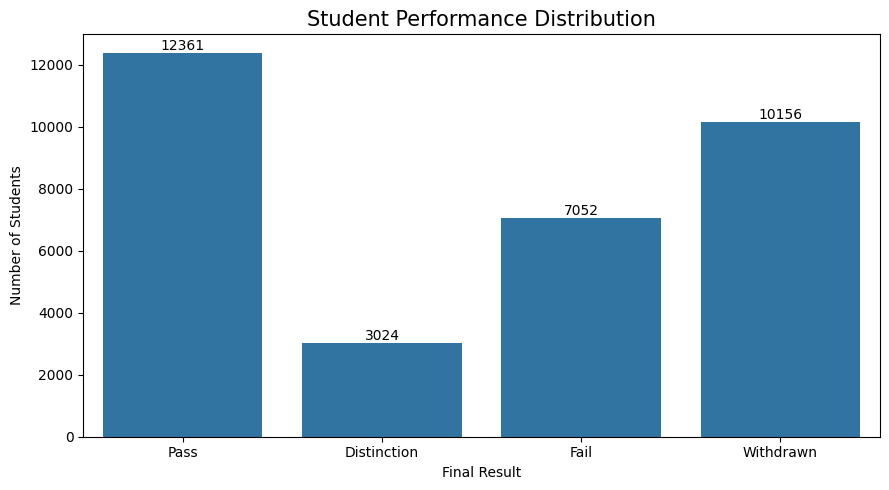

In [99]:
# STEP 32: Student Performance Distribution

import matplotlib.pyplot as plt
import seaborn as sns
import os

# Create folder to save graphs
eda_path = "/content/eda_visualizations"
os.makedirs(eda_path, exist_ok=True)

# Define result order
result_order = ["Pass", "Distinction", "Fail", "Withdrawn"]

# Create count plot
plt.figure(figsize=(9, 5))

ax = sns.countplot(
    data=student_info_clean,
    x="final_result",
    order=result_order
)

# Add count labels
for container in ax.containers:
    ax.bar_label(container)

plt.title("Student Performance Distribution", fontsize=15)
plt.xlabel("Final Result")
plt.ylabel("Number of Students")
plt.tight_layout()

# Save graph
plt.savefig(
    os.path.join(eda_path, "01_student_performance.png"),
    dpi=300
)

plt.show()

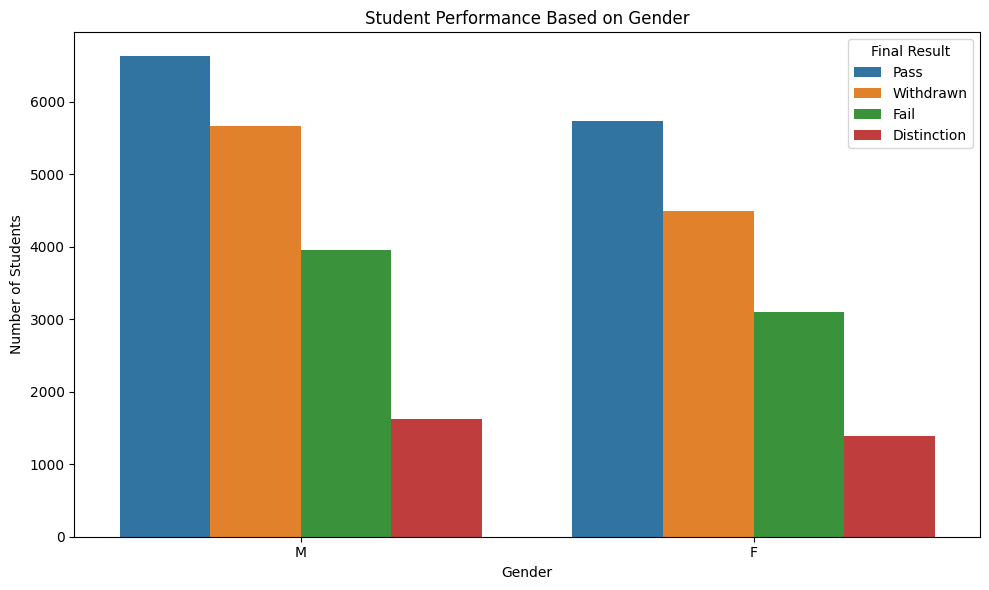

In [100]:
# STEP 33: Student Performance Based on Gender

plt.figure(figsize=(10, 6))

sns.countplot(
    data=student_info_clean,
    x="gender",
    hue="final_result"
)

plt.title("Student Performance Based on Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Students")
plt.legend(title="Final Result")

plt.tight_layout()

plt.savefig(
    os.path.join(eda_path, "02_performance_by_gender.png"),
    dpi=300
)

plt.show()

Gender-wise Performance Percentage:


final_result,Distinction,Fail,Pass,Withdrawn
gender,,,,
F,9.47,21.08,38.97,30.48
M,9.12,22.09,37.07,31.72


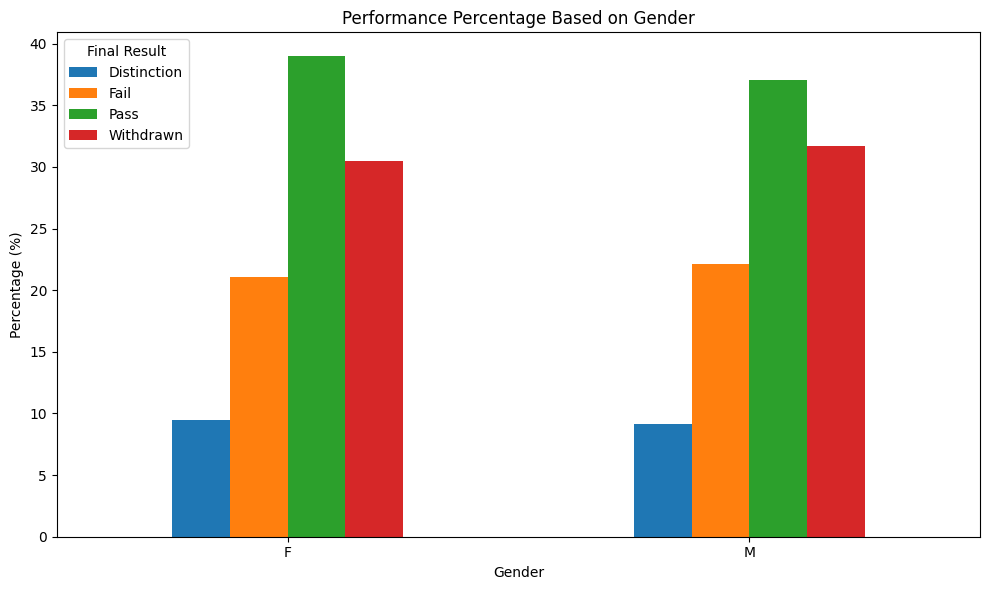

In [101]:
# STEP 34: Gender-wise Performance Percentage

gender_performance = pd.crosstab(
    student_info_clean["gender"],
    student_info_clean["final_result"],
    normalize="index"
) * 100

print("Gender-wise Performance Percentage:")
display(gender_performance.round(2))

# Create percentage chart
gender_performance.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Performance Percentage Based on Gender")
plt.xlabel("Gender")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Final Result")
plt.tight_layout()

plt.savefig(
    os.path.join(eda_path, "03_gender_performance_percentage.png"),
    dpi=300
)

plt.show()

Age-wise Student Performance Percentage:


final_result,Distinction,Fail,Pass,Withdrawn
age_band,,,,
0-35,8.12,22.80,36.91,32.17
35-55,11.87,19.00,40.28,28.85
55<=,18.98,13.43,42.59,25.00


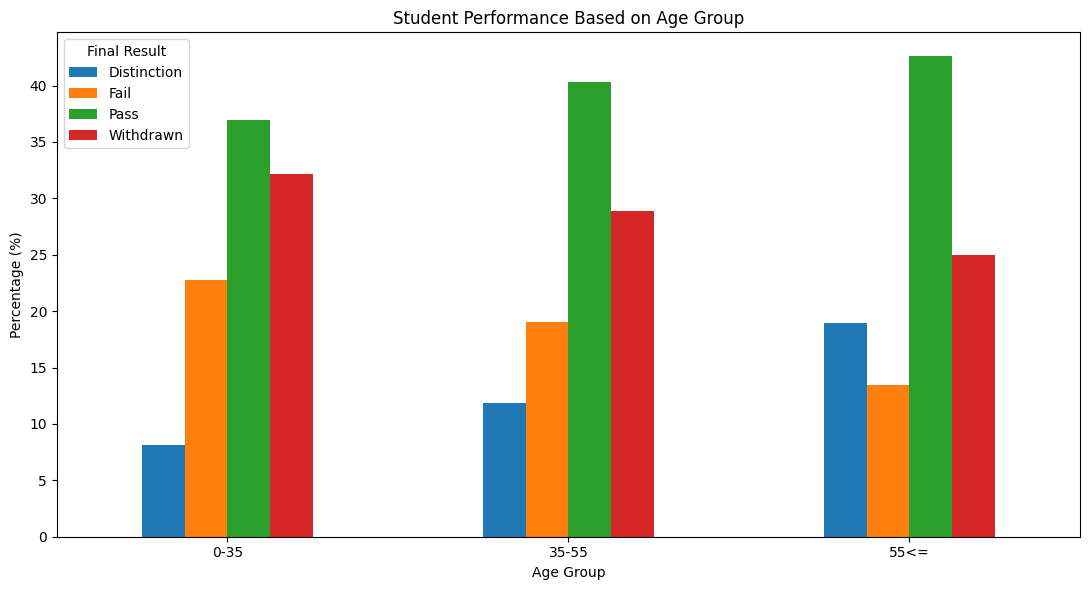

In [102]:
# STEP 35: Performance Based on Age Group

age_performance = pd.crosstab(
    student_info_clean["age_band"],
    student_info_clean["final_result"],
    normalize="index"
) * 100

print("Age-wise Student Performance Percentage:")
display(age_performance.round(2))

# Create graph
age_performance.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Student Performance Based on Age Group")
plt.xlabel("Age Group")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Final Result")
plt.tight_layout()

plt.savefig(
    os.path.join(eda_path, "04_age_group_performance.png"),
    dpi=300
)

plt.show()

Education-wise Student Performance Percentage:


final_result,Distinction,Fail,Pass,Withdrawn
highest_education,,,,
A Level or Equivalent,10.65,19.27,41.38,28.69
HE Qualification,14.74,16.70,41.44,27.12
Lower Than A Level,5.53,26.04,33.33,35.11
No Formal quals,4.61,27.38,25.07,42.94
Post Graduate Qualification,28.12,10.86,37.38,23.64


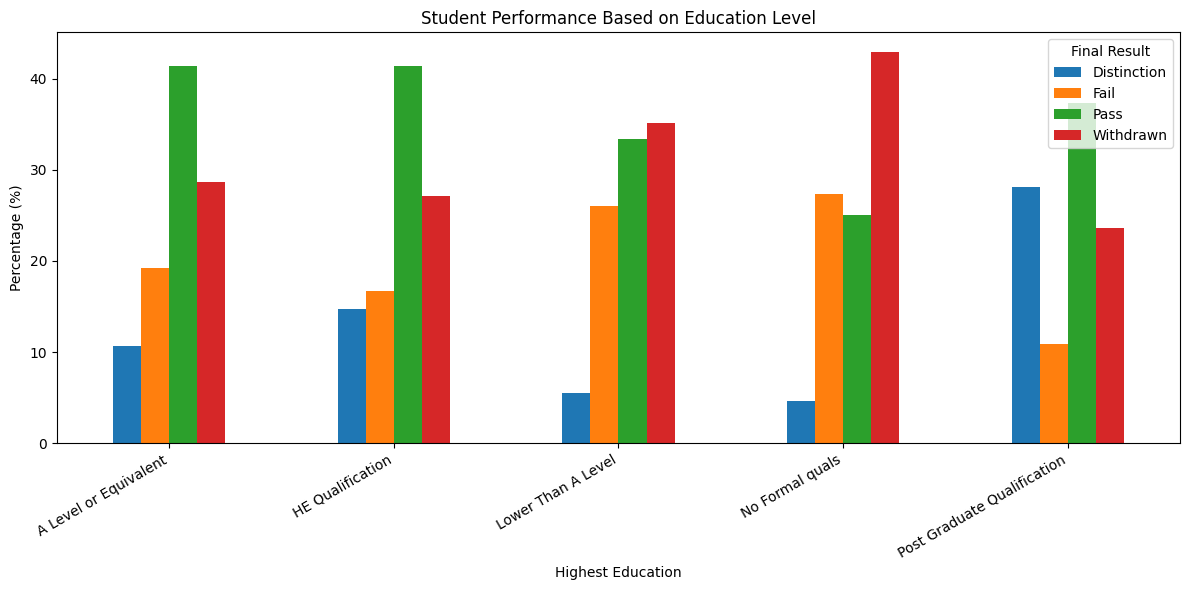

In [103]:
# STEP 36: Performance Based on Education Level

education_performance = pd.crosstab(
    student_info_clean["highest_education"],
    student_info_clean["final_result"],
    normalize="index"
) * 100

print("Education-wise Student Performance Percentage:")

display(education_performance.round(2))

# Create graph
education_performance.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Student Performance Based on Education Level")
plt.xlabel("Highest Education")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=30, ha="right")
plt.legend(title="Final Result")
plt.tight_layout()

plt.savefig(
    os.path.join(eda_path, "05_education_performance.png"),
    dpi=300
)

plt.show()

Previous Attempts-wise Performance Percentage:


final_result,Distinction,Fail,Pass,Withdrawn
num_of_prev_attempts,,,,
0,10.05,20.16,39.22,30.56
1,4.33,30.59,30.22,34.86
2,3.26,34.96,25.19,36.59
3,0.70,40.14,21.83,37.32
4,0.00,30.77,33.33,35.90
5,0.00,46.15,15.38,38.46
6,25.00,25.00,0.00,50.00


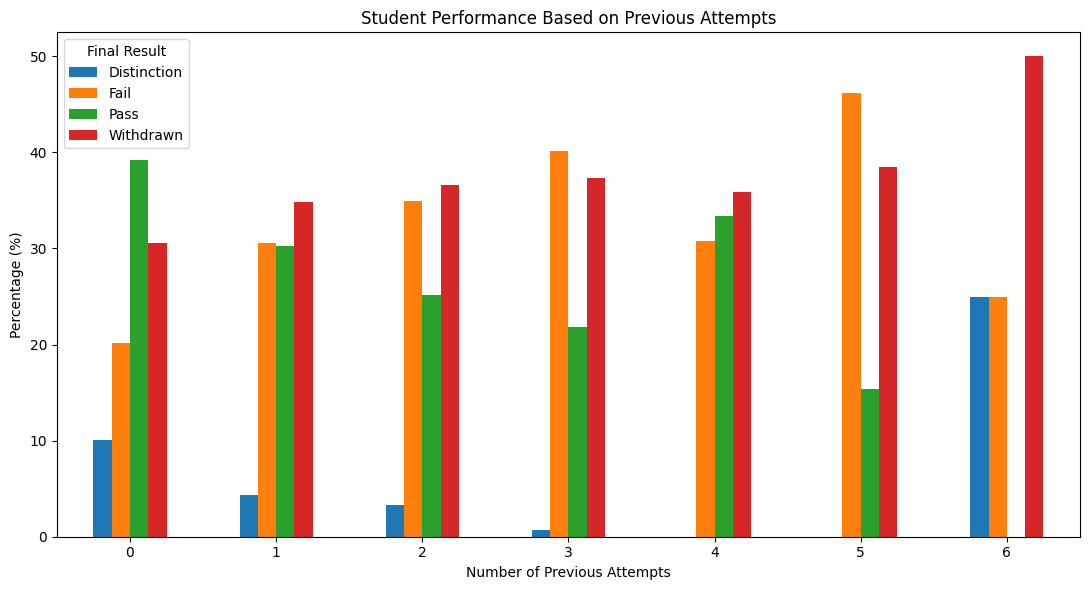

In [104]:
# STEP 37: Performance Based on Previous Attempts

attempt_performance = pd.crosstab(
    student_info_clean["num_of_prev_attempts"],
    student_info_clean["final_result"],
    normalize="index"
) * 100

print("Previous Attempts-wise Performance Percentage:")

display(attempt_performance.round(2))

# Create graph
attempt_performance.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Student Performance Based on Previous Attempts")
plt.xlabel("Number of Previous Attempts")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Final Result")
plt.tight_layout()

plt.savefig(
    os.path.join(eda_path, "06_previous_attempts_performance.png"),
    dpi=300
)

plt.show()

Student Count Based on Previous Attempts:


,Student Count
num_of_prev_attempts,
0,28421
1,3299
2,675
3,142
4,39
5,13
6,4


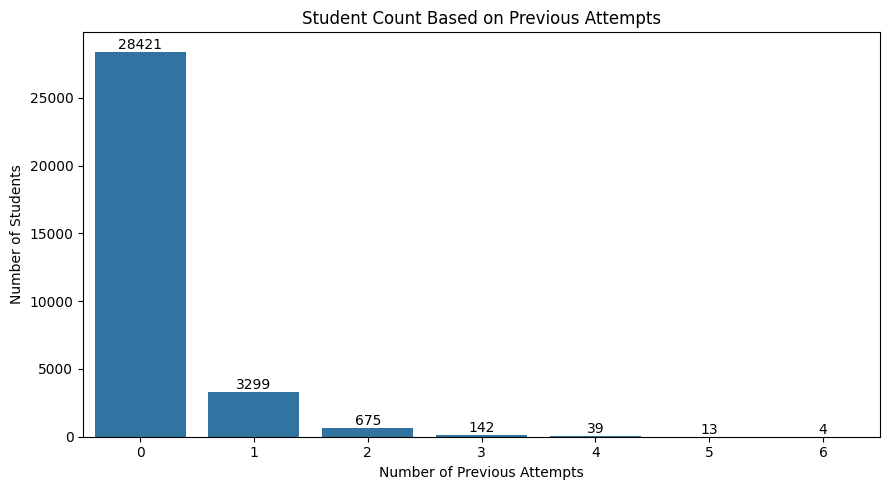

In [105]:
# STEP 38: Student Count Based on Previous Attempts

attempt_counts = student_info_clean[
    "num_of_prev_attempts"
].value_counts().sort_index()

print("Student Count Based on Previous Attempts:")
display(attempt_counts.to_frame(name="Student Count"))

# Visualisation
plt.figure(figsize=(9, 5))

ax = sns.countplot(
    data=student_info_clean,
    x="num_of_prev_attempts"
)

for container in ax.containers:
    ax.bar_label(container)

plt.title("Student Count Based on Previous Attempts")
plt.xlabel("Number of Previous Attempts")
plt.ylabel("Number of Students")
plt.tight_layout()

plt.savefig(
    os.path.join(eda_path, "07_previous_attempts_count.png"),
    dpi=300
)

plt.show()

In [106]:
# STEP 39: Chi-Square Statistical Test

from scipy.stats import chi2_contingency

# Create contingency table
gender_result_table = pd.crosstab(
    student_info_clean["gender"],
    student_info_clean["final_result"]
)

print("Gender vs Final Result:")
display(gender_result_table)

# Perform Chi-Square test
chi2, p_value, dof, expected = chi2_contingency(
    gender_result_table
)

print("Chi-Square Statistic:", round(chi2, 4))
print("P-Value:", p_value)
print("Degrees of Freedom:", dof)

# Interpretation
if p_value < 0.05:
    print("Result: Significant association exists between Gender and Final Result.")
else:
    print("Result: No significant association exists between Gender and Final Result.")

Gender vs Final Result:


final_result,Distinction,Fail,Pass,Withdrawn
gender,,,,
F,1394,3103,5735,4486
M,1630,3949,6626,5670


Chi-Square Statistic: 16.5301
P-Value: 0.0008827203938431326
Degrees of Freedom: 3
Result: Significant association exists between Gender and Final Result.


In [107]:
# STEP 40: Chi-Square Test - Age Group vs Final Result

from scipy.stats import chi2_contingency

# Create contingency table
age_result_table = pd.crosstab(
    student_info_clean["age_band"],
    student_info_clean["final_result"]
)

print("Age Group vs Final Result:")
display(age_result_table)

# Perform Chi-Square test
chi2, p_value, dof, expected = chi2_contingency(
    age_result_table
)

print("Chi-Square Statistic:", round(chi2, 4))
print("P-Value:", p_value)
print("Degrees of Freedom:", dof)

# Interpretation
if p_value < 0.05:
    print("Result: Significant association exists between Age Group and Final Result.")
else:
    print("Result: No significant association exists between Age Group and Final Result.")

Age Group vs Final Result:


final_result,Distinction,Fail,Pass,Withdrawn
age_band,,,,
0-35,1863,5231,8469,7381
35-55,1120,1792,3800,2721
55<=,41,29,92,54


Chi-Square Statistic: 222.6508
P-Value: 2.83109146708854e-45
Degrees of Freedom: 6
Result: Significant association exists between Age Group and Final Result.


In [108]:
# STEP 41: Chi-Square Test - Education vs Final Result

from scipy.stats import chi2_contingency

# Create contingency table
education_result_table = pd.crosstab(
    student_info_clean["highest_education"],
    student_info_clean["final_result"]
)

print("Education vs Final Result:")
display(education_result_table)

# Perform Chi-Square test
chi2, p_value, dof, expected = chi2_contingency(
    education_result_table
)

print("Chi-Square Statistic:", round(chi2, 4))
print("P-Value:", p_value)
print("Degrees of Freedom:", dof)

# Interpretation
if p_value < 0.05:
    print("Result: Significant association exists between Education and Final Result.")
else:
    print("Result: No significant association exists between Education and Final Result.")

Education vs Final Result:


final_result,Distinction,Fail,Pass,Withdrawn
highest_education,,,,
A Level or Equivalent,1496,2707,5812,4030
HE Qualification,697,790,1960,1283
Lower Than A Level,727,3426,4385,4620
No Formal quals,16,95,87,149
Post Graduate Qualification,88,34,117,74


Chi-Square Statistic: 1024.6962
P-Value: 9.18211300726649e-212
Degrees of Freedom: 12
Result: Significant association exists between Education and Final Result.


In [109]:
import pandas as pd, numpy as np
from scipy.stats import chi2_contingency

df = student_info.copy()   # unga cleaned table name

def cramers_v(data, col, target="final_result"):
    ct = pd.crosstab(data[col], data[target])
    chi2, p, dof, _ = chi2_contingency(ct)
    n = ct.values.sum()
    k = min(ct.shape) - 1
    v = np.sqrt(chi2 / (n * k))
    small, medium, large = 0.1/np.sqrt(k), 0.3/np.sqrt(k), 0.5/np.sqrt(k)
    effect = ("negligible" if v < small else "small" if v < medium
              else "medium" if v < large else "large")
    return {"variable": col, "chi2": round(chi2, 2), "dof": dof,
            "p_value": f"{p:.2e}", "cramers_v": round(v, 4), "effect": effect}

effect_table = pd.DataFrame([cramers_v(df, c) for c in ["gender", "age_band", "highest_education"]])
display(effect_table)

,variable,chi2,dof,p_value,cramers_v,effect
0,gender,16.53,3,8.83e-04,0.0225,negligible
1,age_band,222.65,6,2.83e-45,0.0584,negligible
2,highest_education,1024.70,12,9.18e-212,0.1024,small


In [110]:
from statsmodels.stats.proportion import proportion_confint

df["withdrawn"] = (df["final_result"] == "Withdrawn").astype(int)

def dropout_table(data, col, order=None):
    g = data.groupby(col)["withdrawn"].agg(n="size", withdrawn="sum")
    if order:
        g = g.reindex(order)
    g["dropout_rate_%"] = (g["withdrawn"] / g["n"] * 100).round(1)
    lo, hi = proportion_confint(g["withdrawn"], g["n"], alpha=0.05, method="wilson")
    g["CI_low_%"] = (lo * 100).round(1)
    g["CI_high_%"] = (hi * 100).round(1)
    return g

edu_order = ["No Formal quals", "Lower Than A Level", "A Level or Equivalent",
             "HE Qualification", "Post Graduate Qualification"]

print("Dropout rate by education:")
display(dropout_table(df, "highest_education", edu_order))
print("Dropout rate by gender:")
display(dropout_table(df, "gender"))
print("Dropout rate by age band:")
display(dropout_table(df, "age_band", ["0-35", "35-55", "55<="]))

Dropout rate by education:


,n,withdrawn,dropout_rate_%,CI_low_%,CI_high_%
highest_education,,,,,
No Formal quals,347,149,42.9,37.8,48.2
Lower Than A Level,13158,4620,35.1,34.3,35.9
A Level or Equivalent,14045,4030,28.7,28.0,29.4
HE Qualification,4730,1283,27.1,25.9,28.4
Post Graduate Qualification,313,74,23.6,19.3,28.7


Dropout rate by gender:


,n,withdrawn,dropout_rate_%,CI_low_%,CI_high_%
gender,,,,,
F,14718,4486,30.5,29.7,31.2
M,17875,5670,31.7,31.0,32.4


Dropout rate by age band:


,n,withdrawn,dropout_rate_%,CI_low_%,CI_high_%
age_band,,,,,
0-35,22944,7381,32.2,31.6,32.8
35-55,9433,2721,28.8,27.9,29.8
55<=,216,54,25.0,19.7,31.2


In [111]:
from statsmodels.stats.proportion import proportions_ztest

low_edu = ["No Formal quals", "Lower Than A Level"]
df["edu_group"] = np.where(df["highest_education"].isin(low_edu),
                           "Low education", "A Level or higher")

a = df[df["edu_group"] == "Low education"]
b = df[df["edu_group"] == "A Level or higher"]
x1, n1 = a["withdrawn"].sum(), len(a)
x2, n2 = b["withdrawn"].sum(), len(b)
p1, p2 = x1 / n1, x2 / n2

z, p_value = proportions_ztest([x1, x2], [n1, n2])

diff = p1 - p2
se = np.sqrt(p1*(1-p1)/n1 + p2*(1-p2)/n2)
ci_low, ci_high = diff - 1.96*se, diff + 1.96*se
risk_ratio = p1 / p2
cohens_h = 2*np.arcsin(np.sqrt(p1)) - 2*np.arcsin(np.sqrt(p2))

print("H0: dropout rate is the same in both education groups")
print("H1: dropout rate is different")
print(f"\nLow education      : {x1:,} / {n1:,} withdrawn = {p1:.1%}")
print(f"A Level or higher  : {x2:,} / {n2:,} withdrawn = {p2:.1%}")
print(f"\nz = {z:.2f} | p-value = {p_value:.3e}")
print(f"Difference = {diff*100:.1f} percentage points")
print(f"95% CI for difference = [{ci_low*100:.1f}, {ci_high*100:.1f}] percentage points")
print(f"Risk ratio = {risk_ratio:.2f}  (low education students withdraw {risk_ratio:.2f}x as often)")
print(f"Cohen's h = {abs(cohens_h):.2f}  (0.2 small, 0.5 medium, 0.8 large)")
print("\nDecision:", "REJECT H0" if p_value < 0.05 else "FAIL TO REJECT H0")

H0: dropout rate is the same in both education groups
H1: dropout rate is different

Low education      : 4,769 / 13,505 withdrawn = 35.3%
A Level or higher  : 5,387 / 19,088 withdrawn = 28.2%

z = 13.62 | p-value = 3.218e-42
Difference = 7.1 percentage points
95% CI for difference = [6.1, 8.1] percentage points
Risk ratio = 1.25  (low education students withdraw 1.25x as often)
Cohen's h = 0.15  (0.2 small, 0.5 medium, 0.8 large)

Decision: REJECT H0


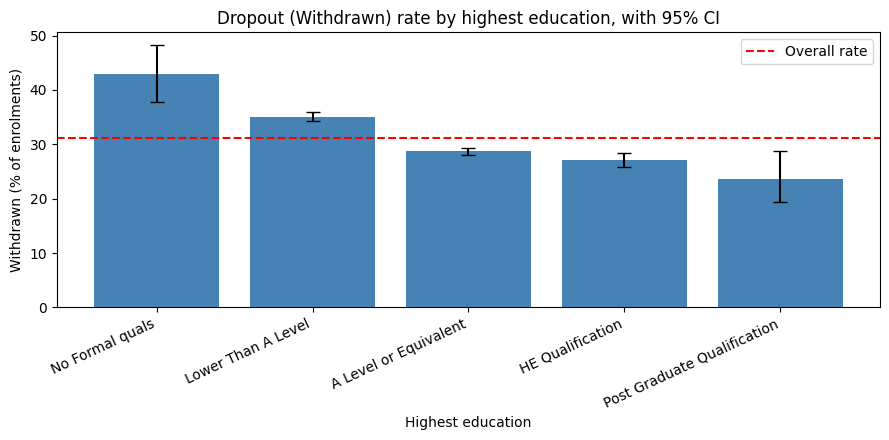

In [112]:
import matplotlib.pyplot as plt

t = dropout_table(df, "highest_education", edu_order)
err = [t["dropout_rate_%"] - t["CI_low_%"], t["CI_high_%"] - t["dropout_rate_%"]]

plt.figure(figsize=(9, 4.5))
plt.bar(t.index, t["dropout_rate_%"], yerr=err, capsize=5, color="steelblue")
plt.axhline(df["withdrawn"].mean() * 100, color="red", linestyle="--", label="Overall rate")
plt.title("Dropout (Withdrawn) rate by highest education, with 95% CI")
plt.ylabel("Withdrawn (% of enrolments)")
plt.xlabel("Highest education")
plt.xticks(rotation=25, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

In [113]:
import pandas as pd, numpy as np

CUTOFF = 30
KEY = ["code_module", "code_presentation", "id_student"]

# 1) Population: only students STILL registered at the cut-off day
reg = student_reg.copy()
reg["date_registration"]   = pd.to_numeric(reg["date_registration"], errors="coerce")
reg["date_unregistration"] = pd.to_numeric(reg["date_unregistration"], errors="coerce")
still = reg[reg["date_unregistration"].isna() | (reg["date_unregistration"] > CUTOFF)]
still = still[KEY + ["date_registration"]]
print(f"Enrolments before filter: {len(reg):,}")
print(f"Still registered at day {CUTOFF}: {len(still):,}")

# 2) Click features (only activity up to the cut-off day)
v = student_vle[student_vle["date"] <= CUTOFF]
click = (v.groupby(KEY, observed=True)
           .agg(total_clicks=("sum_click", "sum"),
                active_days=("date", "nunique"),
                sites_visited=("id_site", "nunique"))
           .reset_index())
for c in ["code_module", "code_presentation"]:
    click[c] = click[c].astype(str)

# 3) Assessment features (only submissions up to the cut-off day)
sa = student_assess.copy()
sa["score"] = pd.to_numeric(sa["score"], errors="coerce")
sa = sa.merge(assessments[["id_assessment", "code_module", "code_presentation"]],
              on="id_assessment", how="left")
sa = sa[sa["date_submitted"] <= CUTOFF]
asm = (sa.groupby(KEY)
         .agg(n_submitted=("id_assessment", "nunique"),
              avg_score=("score", "mean"))
         .reset_index())

# 4) Merge everything into one modelling table (1 row = 1 student-module enrolment)
info_cols = ["gender", "region", "highest_education", "imd_band", "age_band",
             "num_of_prev_attempts", "studied_credits", "disability", "final_result"]
for t in (still, student_info):
    for c in ["code_module", "code_presentation"]:
        t[c] = t[c].astype(str)

data = (still.merge(student_info[KEY + info_cols], on=KEY, how="inner")
             .merge(click, on=KEY, how="left")
             .merge(asm,   on=KEY, how="left"))

for c in ["total_clicks", "active_days", "sites_visited", "n_submitted"]:
    data[c] = data[c].fillna(0)
data["no_submission_yet"] = data["avg_score"].isna().astype(int)

# 5) Target: 1 = Withdrawn, 0 = completed (Pass / Fail / Distinction)
data["withdrawn"] = (data["final_result"] == "Withdrawn").astype(int)

print("\nModelling table shape:", data.shape)
print("\nClass balance (target = withdrawn):")
print(data["withdrawn"].value_counts())
print((data["withdrawn"].value_counts(normalize=True) * 100).round(1))
print("\nMissing values:")
print(data.isna().sum()[data.isna().sum() > 0])
display(data.head())

Enrolments before filter: 32,593
Still registered at day 30: 27,466

Modelling table shape: (27466, 20)

Class balance (target = withdrawn):
withdrawn
0    22429
1     5037
Name: count, dtype: int64
withdrawn
0    81.7
1    18.3
Name: proportion, dtype: float64

Missing values:
date_registration       7
imd_band             1027
avg_score            6618
dtype: int64


,code_module,code_presentation,id_student,date_registration,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result,total_clicks,active_days,sites_visited,n_submitted,avg_score,no_submission_yet,withdrawn
0,AAA,2013J,11391,-159.0,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,Pass,423.0,10.0,26.0,1.0,78.0,0,0
1,AAA,2013J,28400,-53.0,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,Pass,609.0,19.0,34.0,1.0,70.0,0,0
2,AAA,2013J,31604,-52.0,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N,Pass,514.0,24.0,32.0,1.0,72.0,0,0
3,AAA,2013J,32885,-176.0,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N,Pass,559.0,24.0,34.0,1.0,69.0,0,0
4,AAA,2013J,38053,-110.0,M,Wales,A Level or Equivalent,80-90%,35-55,0,60,N,Pass,726.0,33.0,30.0,1.0,79.0,0,0


In [114]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score,
                             recall_score, f1_score, confusion_matrix)

print("Enrolments per presentation:")
print(data["code_presentation"].value_counts().sort_index())

# Temporal split: train on earlier presentations, test on the LATEST presentation
train_pres = ["2013B", "2013J", "2014B"]
test_pres  = ["2014J"]
train = data[data["code_presentation"].isin(train_pres)].copy()
test  = data[data["code_presentation"].isin(test_pres)].copy()

# Remove returning students from the test set so no student appears in both sets
n_before = len(test)
test = test[~test["id_student"].isin(train["id_student"])]
print(f"\nTest rows: {n_before:,} -> {len(test):,} after removing students seen in training")

# Features known at day 30 only. gender / disability / region are NOT used in the model;
# they are kept aside for the fairness check.
num_cols = ["date_registration", "num_of_prev_attempts", "studied_credits",
            "total_clicks", "active_days", "sites_visited",
            "n_submitted", "avg_score", "no_submission_yet"]
cat_cols = ["code_module", "highest_education", "imd_band", "age_band"]

X_train, y_train = train[num_cols + cat_cols], train["withdrawn"]
X_test,  y_test  = test[num_cols + cat_cols],  test["withdrawn"]

print(f"\nTrain: {len(train):,} rows | dropout rate {y_train.mean():.1%}")
print(f"Test : {len(test):,} rows | dropout rate {y_test.mean():.1%}")

def make_pre(scale):
    num_steps = [("imp", SimpleImputer(strategy="median"))]
    if scale:
        num_steps.append(("sc", StandardScaler()))
    return ColumnTransformer([
        ("num", Pipeline(num_steps), num_cols),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="Missing")),
                          ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat_cols)])

Enrolments per presentation:
code_presentation
2013B    4111
2013J    7655
2014B    6497
2014J    9203
Name: count, dtype: int64

Test rows: 9,203 -> 7,921 after removing students seen in training

Train: 18,263 rows | dropout rate 17.9%
Test : 7,921 rows | dropout rate 17.8%


In [115]:
models = {
    "Baseline (always predict base rate)": Pipeline([("pre", make_pre(False)),
                                                    ("m", DummyClassifier(strategy="prior"))]),
    "Logistic Regression": Pipeline([("pre", make_pre(True)),
                                     ("m", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
    "Random Forest": Pipeline([("pre", make_pre(False)),
                               ("m", RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                                            class_weight="balanced_subsample",
                                                            n_jobs=-1, random_state=42))]),
}

rows, probs = [], {}
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    p = pipe.predict_proba(X_test)[:, 1]
    probs[name] = p
    pred = (p >= 0.5).astype(int)
    rows.append({"model": name,
                 "ROC_AUC": roc_auc_score(y_test, p),
                 "PR_AUC": average_precision_score(y_test, p),
                 "precision": precision_score(y_test, pred, zero_division=0),
                 "recall": recall_score(y_test, pred, zero_division=0),
                 "F1": f1_score(y_test, pred, zero_division=0)})

results = pd.DataFrame(rows).set_index("model").round(3)
print(f"Test-set dropout rate (= PR_AUC of a random model): {y_test.mean():.3f}")
display(results)

Test-set dropout rate (= PR_AUC of a random model): 0.178


,ROC_AUC,PR_AUC,precision,recall,F1
model,,,,,
Baseline (always predict base rate),0.500,0.178,0.000,0.000,0.000
Logistic Regression,0.666,0.286,0.287,0.609,0.390
Random Forest,0.688,0.350,0.350,0.376,0.363


In [116]:
best_name = results.drop(index=[i for i in results.index if "Baseline" in i])["PR_AUC"].idxmax()
print("Best model by PR_AUC:", best_name)
p_best = probs[best_name]

cm = confusion_matrix(y_test, (p_best >= 0.5).astype(int))
display(pd.DataFrame(cm, index=["Actual stayed", "Actual withdrew"],
                     columns=["Pred stayed", "Pred withdrew"]))

# Business view: if staff can only contact the top X% highest-risk students
order = np.argsort(-p_best)
y_sorted = y_test.values[order]
rows = []
for pct in [0.05, 0.10, 0.20, 0.30]:
    k = int(len(y_sorted) * pct)
    caught = y_sorted[:k].sum()
    rows.append({"contact_top_%": int(pct * 100), "students_contacted": k,
                 "dropouts_caught": int(caught),
                 "precision_%": round(caught / k * 100, 1),
                 "share_of_all_dropouts_caught_%": round(caught / y_sorted.sum() * 100, 1),
                 "lift_vs_random": round((caught / k) / y_test.mean(), 2)})
pd.set_option("display.width", 200)
display(pd.DataFrame(rows))

Best model by PR_AUC: Random Forest


,Pred stayed,Pred withdrew
Actual stayed,5530,983
Actual withdrew,878,530


,contact_top_%,students_contacted,dropouts_caught,precision_%,share_of_all_dropouts_caught_%,lift_vs_random
0,5,396,206,52.0,14.6,2.93
1,10,792,346,43.7,24.6,2.46
2,20,1584,550,34.7,39.1,1.95
3,30,2376,735,30.9,52.2,1.74


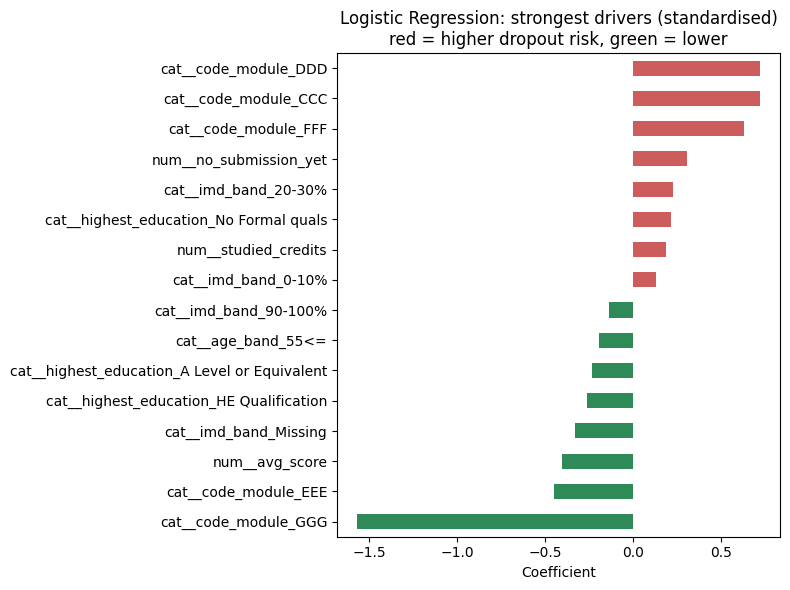

In [117]:
pipe = models["Logistic Regression"]
names = pipe.named_steps["pre"].get_feature_names_out()
coef = pd.Series(pipe.named_steps["m"].coef_[0], index=names).sort_values()
top = pd.concat([coef.head(8), coef.tail(8)])

plt.figure(figsize=(8, 6))
top.plot(kind="barh", color=np.where(top > 0, "indianred", "seagreen"))
plt.title("Logistic Regression: strongest drivers (standardised)\nred = higher dropout risk, green = lower")
plt.xlabel("Coefficient"); plt.tight_layout(); plt.show()

In [118]:
from sklearn.metrics import roc_auc_score

# Flag the top 20% highest-risk students (matches a realistic staff capacity)
THRESH = np.quantile(p_best, 0.80)
fair_df = test[["gender", "disability", "age_band"]].copy()
fair_df["y"]    = y_test.values
fair_df["flag"] = (p_best >= THRESH).astype(int)
fair_df["p"]    = p_best

def fairness_table(col):
    rows = []
    for g, d in fair_df.groupby(col):
        tp = ((d.flag == 1) & (d.y == 1)).sum()
        fp = ((d.flag == 1) & (d.y == 0)).sum()
        fn = ((d.flag == 0) & (d.y == 1)).sum()
        tn = ((d.flag == 0) & (d.y == 0)).sum()
        rows.append({col: g, "n": len(d),
                     "actual_dropout_%": round(d.y.mean() * 100, 1),
                     "flagged_%": round(d.flag.mean() * 100, 1),
                     "recall_%": round(tp / (tp + fn) * 100, 1) if (tp + fn) else np.nan,
                     "precision_%": round(tp / (tp + fp) * 100, 1) if (tp + fp) else np.nan,
                     "false_alarm_rate_%": round(fp / (fp + tn) * 100, 1) if (fp + tn) else np.nan,
                     "AUC": round(roc_auc_score(d.y, d.p), 3) if d.y.nunique() > 1 else np.nan})
    out = pd.DataFrame(rows).set_index(col)
    out["small_group_warning"] = np.where(out["n"] < 200, "n < 200: unreliable", "")
    return out

pd.set_option("display.width", 220)
print(f"Threshold = top 20% risk score ({THRESH:.3f}); overall flagged = {fair_df.flag.mean():.1%}")
for c in ["gender", "disability", "age_band"]:
    print(f"\n--- Fairness check by {c} ---")
    display(fairness_table(c))

Threshold = top 20% risk score (0.494); overall flagged = 20.0%

--- Fairness check by gender ---


,n,actual_dropout_%,flagged_%,recall_%,precision_%,false_alarm_rate_%,AUC,small_group_warning
gender,,,,,,,,
F,3549,17.2,19.1,35.6,32.0,15.7,0.660,
M,4372,18.3,20.7,41.7,36.8,16.0,0.711,



--- Fairness check by disability ---


,n,actual_dropout_%,flagged_%,recall_%,precision_%,false_alarm_rate_%,AUC,small_group_warning
disability,,,,,,,,
N,7221,16.9,19.5,38.5,33.4,15.6,0.686,
Y,700,26.9,25.4,42.6,44.9,19.1,0.699,



--- Fairness check by age_band ---


,n,actual_dropout_%,flagged_%,recall_%,precision_%,false_alarm_rate_%,AUC,small_group_warning
age_band,,,,,,,,
0-35,5435,18.0,21.7,41.8,34.7,17.2,0.691,
35-55,2414,17.2,16.6,32.9,34.2,13.2,0.683,
55<=,72,19.4,11.1,28.6,50.0,6.9,0.730,n < 200: unreliable


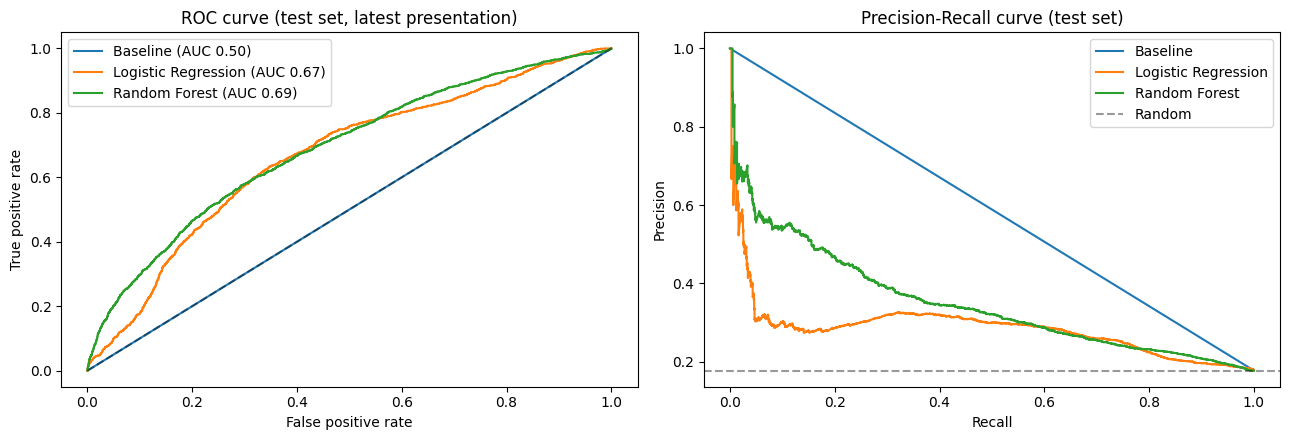

In [119]:
from sklearn.metrics import precision_recall_curve, roc_curve

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for name, p in probs.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    ax[0].plot(fpr, tpr, label=f"{name.split(' (')[0]} (AUC {roc_auc_score(y_test, p):.2f})")
    pr, rc, _ = precision_recall_curve(y_test, p)
    ax[1].plot(rc, pr, label=name.split(' (')[0])
ax[0].plot([0, 1], [0, 1], "k--", alpha=.4)
ax[0].set_title("ROC curve (test set, latest presentation)")
ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate"); ax[0].legend()
ax[1].axhline(y_test.mean(), color="k", linestyle="--", alpha=.4, label="Random")
ax[1].set_title("Precision-Recall curve (test set)")
ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision"); ax[1].legend()
plt.tight_layout(); plt.show()


Day range in VLE data: -25 to 269 (days relative to course start; negative = before start)

Weeks of data per presentation:


,min,max,count
code_presentation,,,
2013B,0,34,35
2013J,0,38,39
2014B,0,34,35
2014J,0,38,39


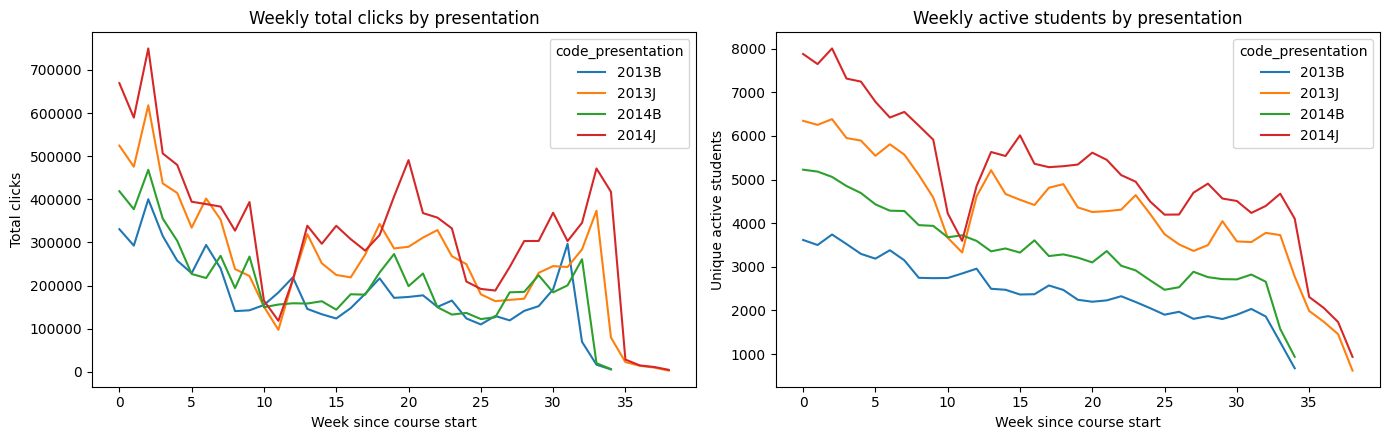

,code_presentation,week,total_clicks,active_students
0,2013B,0,330757,3615
1,2013B,1,292673,3500
2,2013B,2,400090,3740
3,2013B,3,314954,3522
4,2013B,4,257878,3296
5,2013B,5,228757,3187
6,2013B,6,294176,3380
7,2013B,7,240010,3149
8,2013B,8,140870,2748
9,2013B,9,142736,2740


In [120]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

VLE = student_vle_clean      # <<< edit if your cleaned VLE table has a different name

print("Day range in VLE data:", VLE["date"].min(), "to", VLE["date"].max(),
      "(days relative to course start; negative = before start)")

# Only days from course start onwards, grouped into course weeks
v = VLE[VLE["date"] >= 0].copy()
v["week"] = v["date"] // 7
v["code_presentation"] = v["code_presentation"].astype(str)

weekly = (v.groupby(["code_presentation", "week"], observed=True)
            .agg(total_clicks=("sum_click", "sum"),
                 active_students=("id_student", "nunique"))
            .reset_index())

print("\nWeeks of data per presentation:")
display(weekly.groupby("code_presentation")["week"].agg(["min", "max", "count"]))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.lineplot(data=weekly, x="week", y="total_clicks", hue="code_presentation", ax=ax[0])
ax[0].set_title("Weekly total clicks by presentation")
ax[0].set_xlabel("Week since course start"); ax[0].set_ylabel("Total clicks")
sns.lineplot(data=weekly, x="week", y="active_students", hue="code_presentation", ax=ax[1])
ax[1].set_title("Weekly active students by presentation")
ax[1].set_xlabel("Week since

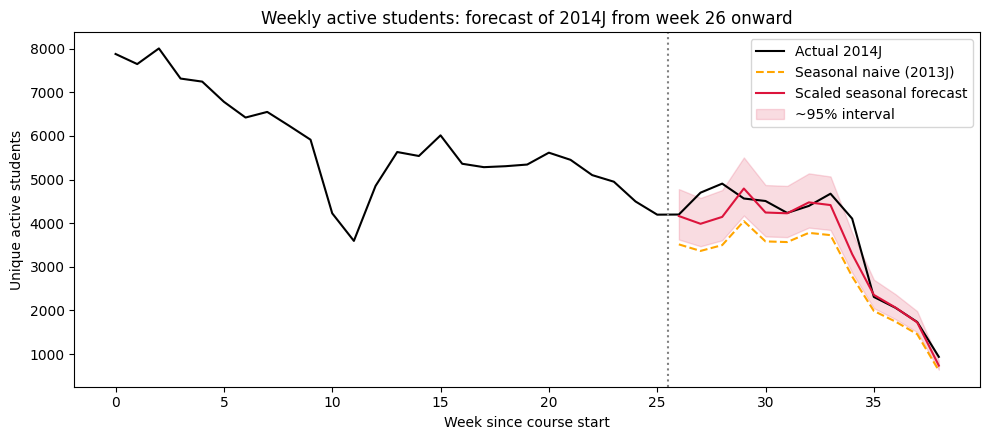

2014J: weeks 0-25 observed, weeks 26-38 forecast (13 weeks)
Interval coverage on test weeks: 69% of actual weeks inside the band


,MAE,MAPE_%,WAPE_%
Naive (last week),957.5,56.4,26.3
Seasonal naive (2013J),743.5,20.5,20.4
Scaled seasonal (2013J x 1.18),263.7,7.2,7.2


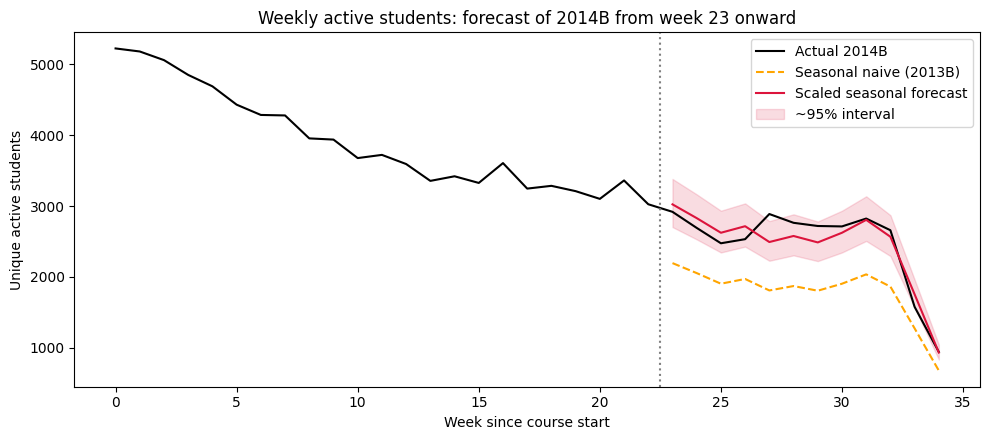

2014B: weeks 0-22 observed, weeks 23-34 forecast (12 weeks)
Interval coverage on test weeks: 92% of actual weeks inside the band


,MAE,MAPE_%,WAPE_%
Naive (last week),550.8,35.8,22.3
Seasonal naive (2013B),695.1,27.7,28.1
Scaled seasonal (2013B x 1.38),147.7,5.9,6.0


In [121]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

METRIC = "active_students"     # quantity to forecast: unique students active per week

def seasonal_forecast(weekly, ref, target, K, metric=METRIC):
    r = weekly[weekly.code_presentation == ref].set_index("week")[metric].astype(float)
    t = weekly[weekly.code_presentation == target].set_index("week")[metric].astype(float)
    weeks = sorted(set(r.index) & set(t.index))
    obs = [w for w in weeks if w < K]          # weeks we "know" (training period)
    fut = [w for w in weeks if w >= K]         # later weeks we forecast (test period)

    # Baseline 1: naive - repeat the last observed week
    naive = pd.Series(t.loc[obs].iloc[-1], index=fut)
    # Baseline 2: seasonal naive - same week of the reference presentation
    seas = r.loc[fut]
    # Method: scaled seasonal - reference shape x (target level / reference level)
    scale = t.loc[obs].sum() / r.loc[obs].sum()
    scaled = r.loc[fut] * scale

    # Uncertainty: spread of the scaling error over the observed weeks
    lr = np.log((t.loc[obs] / (r.loc[obs] * scale)).replace(0, np.nan).dropna())
    sd = lr.std(ddof=1)
    lo, hi = scaled * np.exp(-1.96 * sd), scaled * np.exp(1.96 * sd)

    actual = t.loc[fut]
    def score(pred):
        e = actual - pred
        return {"MAE": round(e.abs().mean(), 1),
                "MAPE_%": round((e.abs() / actual).mean() * 100, 1),
                "WAPE_%": round(e.abs().sum() / actual.sum() * 100, 1)}
    table = pd.DataFrame({"Naive (last week)": score(naive),
                          f"Seasonal naive ({ref})": score(seas),
                          f"Scaled seasonal ({ref} x {scale:.2f})": score(scaled)}).T
    coverage = ((actual >= lo) & (actual <= hi)).mean() * 100

    plt.figure(figsize=(10, 4.5))
    plt.plot(t.index, t.values, color="black", label=f"Actual {target}")
    plt.plot(fut, seas.values, "--", color="orange", label=f"Seasonal naive ({ref})")
    plt.plot(fut, scaled.values, color="crimson", label="Scaled seasonal forecast")
    plt.fill_between(fut, lo.values, hi.values, color="crimson", alpha=.15, label="~95% interval")
    plt.axvline(K - 0.5, color="grey", linestyle=":")
    plt.title(f"Weekly active students: forecast of {target} from week {K} onward")
    plt.xlabel("Week since course start")
    plt.ylabel("Unique active students")
    plt.legend()
    plt.tight_layout()
    plt.show()

    print(f"{target}: weeks 0-{K-1} observed, weeks {K}-{max(fut)} forecast ({len(fut)} weeks)")
    print(f"Interval coverage on test weeks: {coverage:.0f}% of actual weeks inside the band")
    display(table)
    return table

# Primary evaluation: October-start presentations (2013J -> 2014J)
tab_J = seasonal_forecast(weekly, ref="2013J", target="2014J", K=26)

# Second check: February-start presentations (2013B -> 2014B)
tab_B = seasonal_forecast(weekly, ref="2013B", target="2014B", K=23)

In [122]:
import pandas as pd, numpy as np

# ---------- A) Priority segments: where are the extra withdrawals? ----------
overall = data["withdrawn"].mean()
print(f"Overall withdrawal rate after day 30: {overall:.1%}")

def segment_table(cols, min_n=200):
    g = (data.groupby(cols)
             .agg(n=("withdrawn", "size"), withdrawn=("withdrawn", "sum"))
             .reset_index())
    g["dropout_rate_%"] = (g["withdrawn"] / g["n"] * 100).round(1)
    g["excess_dropouts"] = (g["withdrawn"] - g["n"] * overall).round(0)   # above the overall rate
    return g[g["n"] >= min_n].sort_values("excess_dropouts", ascending=False)

print("\nBy module:")
display(segment_table(["code_module"]))
print("\nTop 10 module x education segments (n >= 200):")
display(segment_table(["code_module", "highest_education"]).head(10))

# ---------- B) Scenario analysis: how many students could outreach retain? ----------
# !!! These three numbers are ASSUMPTIONS, not results from the data. Change them. !!!
COST_PER_CONTACT   = 5      # cost of one outreach (tutor call / message), in your currency
VALUE_PER_RETAINED = 100    # value of keeping one student until the end of the course
RETENTION_RATES    = [0.05, 0.10, 0.20]   # share of reached at-risk students who stay because of outreach

order = np.argsort(-p_best)
y_sorted = y_test.values[order]

rows = []
for pct in [0.05, 0.10, 0.20, 0.30]:
    k = int(len(y_sorted) * pct)
    reached = int(y_sorted[:k].sum())          # students who really would withdraw, among those contacted
    for r in RETENTION_RATES:
        retained = reached * r
        cost = k * COST_PER_CONTACT
        rows.append({"contact_top_%": int(pct * 100),
                     "students_contacted": k,
                     "true_at_risk_reached": reached,
                     "assumed_retention_%": int(r * 100),
                     "students_retained": round(retained, 1),
                     "total_cost": cost,
                     "cost_per_retained": round(cost / retained, 1) if retained else np.nan,
                     "net_value": round(retained * VALUE_PER_RETAINED - cost)})
scen = pd.DataFrame(rows)
pd.set_option("display.width", 220)
print("\nScenario table (test presentation):")
display(scen)

Overall withdrawal rate after day 30: 18.3%

By module:


,code_module,n,withdrawn,dropout_rate_%,excess_dropouts
2,CCC,3503,1044,29.8,402.0
3,DDD,5263,1244,23.6,279.0
5,FFF,6577,1221,18.6,15.0
0,AAA,717,95,13.2,-36.0
4,EEE,2552,340,13.3,-128.0
6,GGG,2435,193,7.9,-254.0
1,BBB,6419,900,14.0,-277.0



Top 10 module x education segments (n >= 200):


,code_module,highest_education,n,withdrawn,dropout_rate_%,excess_dropouts
11,CCC,Lower Than A Level,943,356,37.8,183.0
16,DDD,Lower Than A Level,1828,498,27.2,163.0
9,CCC,A Level or Equivalent,1625,450,27.7,152.0
26,FFF,Lower Than A Level,2674,614,23.0,124.0
14,DDD,A Level or Equivalent,2456,522,21.3,72.0
10,CCC,HE Qualification,807,211,26.1,63.0
15,DDD,HE Qualification,881,194,22.0,32.0
21,EEE,Lower Than A Level,875,144,16.5,-16.0
0,AAA,A Level or Equivalent,379,51,13.5,-19.0
20,EEE,HE Qualification,508,57,11.2,-36.0



Scenario table (test presentation):


,contact_top_%,students_contacted,true_at_risk_reached,assumed_retention_%,students_retained,total_cost,cost_per_retained,net_value
0,5,396,206,5,10.3,1980,192.2,-950
1,5,396,206,10,20.6,1980,96.1,80
2,5,396,206,20,41.2,1980,48.1,2140
3,10,792,346,5,17.3,3960,228.9,-2230
4,10,792,346,10,34.6,3960,114.5,-500
5,10,792,346,20,69.2,3960,57.2,2960
6,20,1584,550,5,27.5,7920,288.0,-5170
7,20,1584,550,10,55.0,7920,144.0,-2420
8,20,1584,550,20,110.0,7920,72.0,3080
9,30,2376,735,5,36.8,11880,323.3,-8205


In [123]:
import pandas as pd, numpy as np

checks = []
def check(name, fn):
    try:
        ok = bool(fn())
    except Exception as e:
        ok = False
        name = f"{name}  (error: {type(e).__name__}: {e})"
    checks.append({"check": name, "result": "PASS" if ok else "FAIL"})

KEY = ["code_module", "code_presentation", "id_student"]
FORBIDDEN_FEATURES = ["final_result", "withdrawn", "date_unregistration", "id_student",
                      "gender", "disability", "region"]
PII_COLUMNS = ["first_name", "last_name", "email", "phone", "name", "address"]

check("Modelling table: one row per student-module enrolment (no duplicate keys)",
      lambda: not data.duplicated(subset=KEY).any())
check("Target 'withdrawn' contains only 0/1 and no missing values",
      lambda: set(data["withdrawn"].unique()) <= {0, 1} and data["withdrawn"].notna().all())
check("Target has both classes in train and test",
      lambda: train["withdrawn"].nunique() == 2 and test["withdrawn"].nunique() == 2)
check("No leakage / sensitive columns used as model features",
      lambda: not set(FORBIDDEN_FEATURES) & set(num_cols + cat_cols))
check("No student appears in both train and test",
      lambda: len(set(train["id_student"]) & set(test["id_student"])) == 0)
check("Temporal split: every test presentation is later than all train presentations",
      lambda: min(test["code_presentation"]) > max(train["code_presentation"]))
check("No personal-identifier columns in modelling table",
      lambda: not set(PII_COLUMNS) & set(c.lower() for c in data.columns))
check("Random Forest has a fixed random_state (reproducible)",
      lambda: models["Random Forest"].named_steps["m"].random_state is not None)
check("Best model beats the baseline on PR-AUC",
      lambda: results.loc[best_name, "PR_AUC"] > results.iloc[0]["PR_AUC"])
check("Weekly forecast table has no negative or missing values",
      lambda: (weekly[["total_clicks", "active_students"]] >= 0).all().all()
              and weekly[["total_clicks", "active_students"]].notna().all().all())

report = pd.DataFrame(checks)
pd.set_option("display.max_colwidth", 120)
display(report)
print(f"\n{(report.result == 'PASS').sum()} of {len(report)} checks passed")

,check,result
0,Modelling table: one row per student-module enrolment (no duplicate keys),PASS
1,Target 'withdrawn' contains only 0/1 and no missing values,PASS
2,Target has both classes in train and test,PASS
3,No leakage / sensitive columns used as model features,PASS
4,No student appears in both train and test,PASS
5,Temporal split: every test presentation is later than all train presentations,PASS
6,No personal-identifier columns in modelling table,PASS
7,Random Forest has a fixed random_state (reproducible),PASS
8,Best model beats the baseline on PR-AUC,PASS
9,Weekly forecast table has no negative or missing values,PASS



10 of 10 checks passed
